<a href="https://colab.research.google.com/github/OAKVISUALZ/Pytorch/blob/main/04_pytorch_custom_datasets.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#04. PyTorch Custom Datasets Video Notebook

We've used some datasets with PyTorch before.

But how do you get your own data into PyTorch?

One of the ways to do so is via: custom Datasets

## Doman libraries

Depending on what's you're working on, vision, text, audio. recommendation, you'll want to look into each of the Pytorch exsiting data loading functions and customizable data loading functions


**Resources**
* Book version of the course materials
* Ground truth version

0. Importing PyTorch and setting up device-agnostic code

In [662]:
import torch
from torch import nn

# Note: PyTorch 1.10 is required
torch.__version__

'2.11.0+cpu'

In [663]:
# Setup device-agnostic code
device = "cuda" if torch.cuda.is_available() else 'cpu'
device

'cpu'

In [664]:
!nvidia-smi

/bin/bash: line 1: nvidia-smi: command not found


# 1. Get data

Our dataset is a subset of the Food101 dataset.

Food101 starts 101 different classes of food and 1000 images per class (750 training, 250 testing).

Our dataset starts with 3 classes of food and onlu 10 % of the images(~75 training, 25 testing).
Why do this?
when starting out ML projects, it's important to try things on a small scale and then increase the scale when neccessary.

The whole point is to speed up how fast you can experiment

In [665]:
import requests
import zipfile
from pathlib import Path

# Setup path to a data folder
data_path = Path("data/")
image_path = data_path / "pizza_steak_sushi"

# If the image folder doesn't exist, download it and prepare it...
if image_path.is_dir():
  print(f"{image_path} directory exists.")
else:
  print(f"Did not find {image_path} directory, creating one...")
  image_path.mkdir(parents=True, exist_ok=True)

# Download pizza, steak and sushi data
with open(data_path / "pizza_steak_sushi.zip", "wb") as f:
  request = requests.get("https://github.com/mrdbourke/pytorch-deep-learning/raw/main/data/pizza_steak_sushi.zip")
  print("Downloading pizza, steak, sushi data...")
  f.write(request.content)

# Unzip pizza, steak, sushi data
with zipfile.ZipFile(data_path / "pizza_steak_sushi.zip", "r") as zip_ref:
  print("Unzipping pizza, steak, sushi data...")
  zip_ref.extractall(image_path)

data/pizza_steak_sushi directory exists.
Unzipping pizza, steak, sushi data...


### 2. Becoming one with the data  (data preparation and data exploration)

In [666]:
import os
def walk_through_dir(dir_path):
  """Walks through dir_path returning its contents."""
  for dirpath, dirnames, filenames in os.walk(dir_path):
    print(f"There are {len(dirnames)} directories and {len(filenames)} images in '{dirpath}'.")

In [667]:
walk_through_dir(image_path)

There are 2 directories and 0 images in 'data/pizza_steak_sushi'.
There are 3 directories and 0 images in 'data/pizza_steak_sushi/train'.
There are 0 directories and 78 images in 'data/pizza_steak_sushi/train/pizza'.
There are 0 directories and 72 images in 'data/pizza_steak_sushi/train/sushi'.
There are 0 directories and 75 images in 'data/pizza_steak_sushi/train/steak'.
There are 3 directories and 0 images in 'data/pizza_steak_sushi/test'.
There are 0 directories and 25 images in 'data/pizza_steak_sushi/test/pizza'.
There are 0 directories and 31 images in 'data/pizza_steak_sushi/test/sushi'.
There are 0 directories and 19 images in 'data/pizza_steak_sushi/test/steak'.


In [668]:
# Setup train and testing paths
train_dir = image_path / "train"
test_dir = image_path / "test"

train_dir, test_dir

(PosixPath('data/pizza_steak_sushi/train'),
 PosixPath('data/pizza_steak_sushi/test'))

### 2.2 Visualizing and Image

Let's write some code to:
1. Get all of the image paths
2. Pick a random image path using PYthon's random.choice()
3. Get the image class name  using 'pathlib.Path.parent.stem'
4. Since we're working with images, let's open the image with Python's PIL
5. We'll then show the image and print metadata

In [669]:
image_path

PosixPath('data/pizza_steak_sushi')

Random image path: data/pizza_steak_sushi/train/pizza/2426686.jpg
Image class: pizza
Random image path: data/pizza_steak_sushi/train/pizza/2426686.jpg
Image class: pizza
Image height: 341
Image width: 512


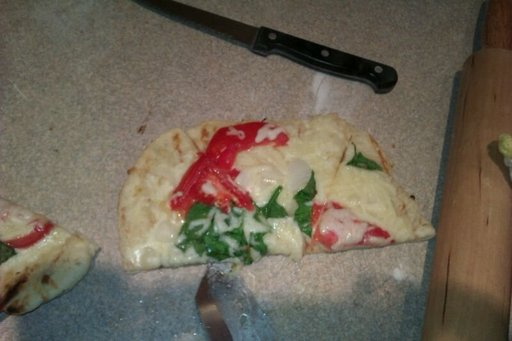

In [670]:
import random
from PIL import Image

# Set seed
#random.seed(42)

# 1. Get all image paths
image_path_list = list(image_path.glob("*/*/*.jpg"))

# 2. Pick a random image path
random_image_path = random.choice(image_path_list)
print(f"Random image path: {random_image_path}")

# 3. Get image class from path name ( the image class is the name of the dirctory where the)

image_class = random_image_path.parent.stem
print(f"Image class: {image_class}")

# 4. Open image
img = Image.open(random_image_path)

#5. Print meatadata
print(f"Random image path: {random_image_path}")
print(f"Image class: {image_class}")
print(f"Image height: {img.height}")
print(f"Image width: {img.width}")
img

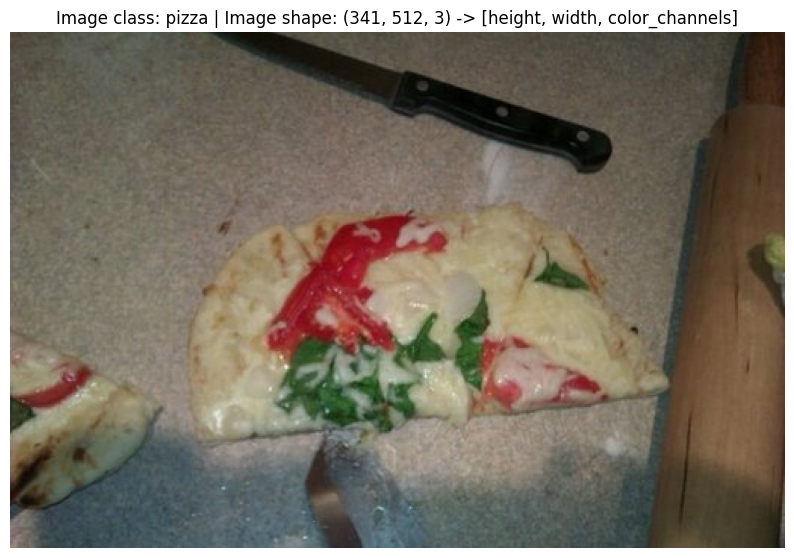

In [671]:
import numpy as np
import matplotlib.pyplot as plt

# Turn the image into an array
img_as_array = np.asarray(img)

# Plot the image with matplotlib
plt.figure(figsize=(10,7))
plt.imshow(img_as_array)
plt.title(f"Image class: {image_class} | Image shape: {img_as_array.shape} -> [height, width, color_channels]")
plt.axis(False);

array([[[ 85,  77,  66],
        [ 82,  74,  63],
        [ 82,  74,  63],
        ...,
        [ 50,  30,  19],
        [ 51,  33,  23],
        [ 52,  34,  24]],

       [[ 86,  78,  67],
        [ 82,  74,  63],
        [ 81,  73,  62],
        ...,
        [ 49,  29,  18],
        [ 50,  32,  22],
        [ 51,  33,  23]],

       [[ 81,  73,  62],
        [ 77,  69,  58],
        [ 75,  67,  56],
        ...,
        [ 47,  27,  16],
        [ 49,  29,  20],
        [ 51,  31,  22]],

       ...,

       [[135, 123, 111],
        [139, 127, 115],
        [147, 134, 126],
        ...,
        [ 66,  65,  60],
        [ 70,  69,  65],
        [ 61,  60,  56]],

       [[146, 134, 122],
        [147, 135, 123],
        [151, 138, 130],
        ...,
        [ 60,  59,  54],
        [ 66,  65,  61],
        [ 60,  59,  55]],

       [[145, 133, 121],
        [144, 132, 120],
        [145, 132, 124],
        ...,
        [ 54,  53,  48],
        [ 62,  61,  57],
        [ 61,  60,  56]]], dtype=uint8)
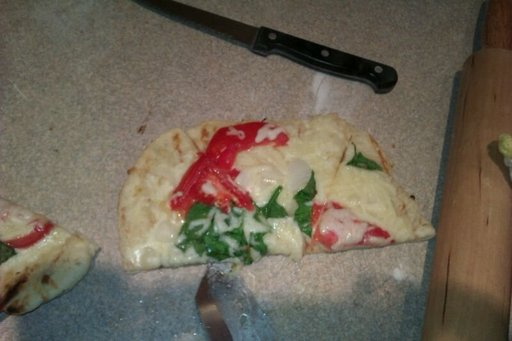

In [672]:
img_as_array

## 3. Transforming data

Before we can use our image data with PyTorch:

1. Turn your target data into tensors (in our case, numerical representation of our images).

2. Turn it into  a torch.utils.data.Dataset and subsequentl a torch.utils.data
Dataloader



In [673]:
import torch
from torch.utils.data import DataLoader
from torchvision import datasets, transforms



### 3.1 Transforming data with torchvision.transforms

Transforms help you get images ready to be used with a model/perform data augmentation

In [674]:
# write  a transform for images
data_transform = transforms.Compose([
    # Resize the images to
    transforms.Resize(size=(64, 64)),
    # Flip the images randomly on the horizontal
    transforms.RandomHorizontalFlip(p=0.5),
    # Turn the image into a torch.Tensor
    transforms.ToTensor()
])




In [675]:
data_transform(img)

tensor([[[0.3098, 0.3137, 0.3137,  ..., 0.1529, 0.1882, 0.1961],
         [0.3216, 0.3176, 0.3294,  ..., 0.1647, 0.2078, 0.2039],
         [0.3333, 0.3294, 0.3451,  ..., 0.1765, 0.2235, 0.2196],
         ...,
         [0.4863, 0.4196, 0.2980,  ..., 0.2353, 0.1961, 0.2078],
         [0.5020, 0.4314, 0.3020,  ..., 0.2275, 0.1882, 0.1922],
         [0.5216, 0.4314, 0.3098,  ..., 0.2314, 0.1882, 0.1725]],

        [[0.2824, 0.2980, 0.3059,  ..., 0.1098, 0.1098, 0.1098],
         [0.2941, 0.3020, 0.3176,  ..., 0.1137, 0.1216, 0.1137],
         [0.3098, 0.3176, 0.3333,  ..., 0.1137, 0.1294, 0.1255],
         ...,
         [0.4431, 0.4118, 0.3255,  ..., 0.2157, 0.1725, 0.1961],
         [0.4510, 0.4157, 0.3333,  ..., 0.2118, 0.1725, 0.1843],
         [0.4745, 0.4118, 0.3373,  ..., 0.2118, 0.1765, 0.1725]],

        [[0.2392, 0.2510, 0.2471,  ..., 0.0627, 0.0510, 0.0588],
         [0.2471, 0.2549, 0.2667,  ..., 0.0627, 0.0588, 0.0588],
         [0.2627, 0.2667, 0.2863,  ..., 0.0588, 0.0667, 0.

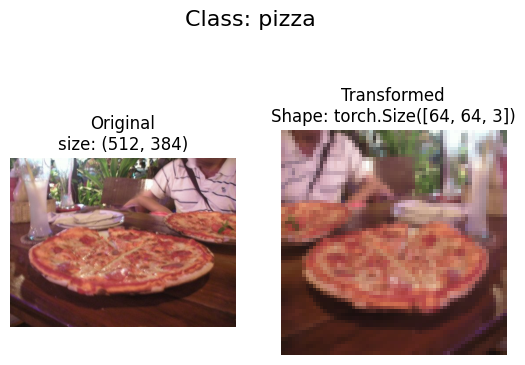

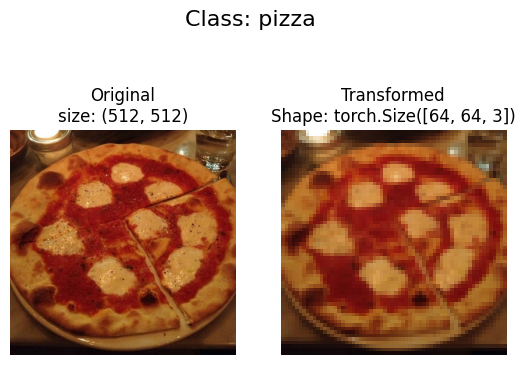

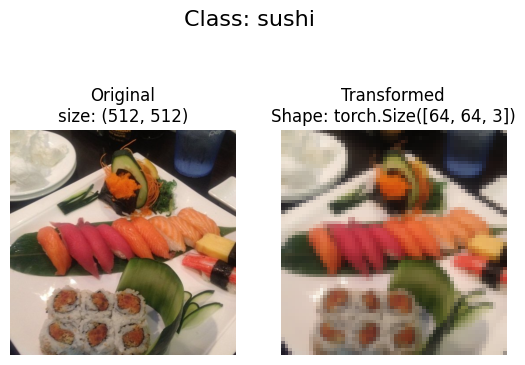

In [676]:
def plot_transformed_images(image_paths, transform, n=3, seed=42):
  """
  Selects random images from a path of images and loads/transforms
  them then plots the original vs the transformed version.
  """
  if seed:
    random.seed(seed)
  random_image_path = random.sample(image_paths, k=n)
  for image_path in random_image_path:
    with Image.open(image_path) as f:
      fig, ax = plt.subplots(nrows=1, ncols=2)
      ax[0].imshow(f)
      ax[0].set_title(f"Original\nsize: {f.size}")
      ax[0].axis(False)

      # Transform and plot target image
      transformed_image = transform(f).permute(1, 2, 0) # note we will need to change shape for matplotlib (C, H, W) -> (H, W, C)
      ax[1].imshow(transformed_image)
      ax[1].set_title(f"Transformed\nShape: {transformed_image.shape}")
      ax[1].axis("off")

      fig.suptitle(f"Class: {image_path.parent.stem}", fontsize=16)

plot_transformed_images(image_paths=image_path_list,
                        transform=data_transform,
                        n=3,
                        seed=42)


## 4. Option loading image data using 'ImageFolder'

We can load image classification data using torchvision.datasets.ImageFolder

In [677]:
# Use Imagefolder to create dataset(s)

from torchvision import datasets
train_data = datasets.ImageFolder(root=train_dir, # target folder of images
                                  transform=data_transform, # transforms to perform on data (images)
                                  target_transform=None) # transforms to perform on labels (if necessary)

test_data = datasets.ImageFolder(root=test_dir,
                                 transform=data_transform)

train_data, test_data

(Dataset ImageFolder
     Number of datapoints: 225
     Root location: data/pizza_steak_sushi/train
     StandardTransform
 Transform: Compose(
                Resize(size=(64, 64), interpolation=bilinear, max_size=None, antialias=True)
                RandomHorizontalFlip(p=0.5)
                ToTensor()
            ),
 Dataset ImageFolder
     Number of datapoints: 75
     Root location: data/pizza_steak_sushi/test
     StandardTransform
 Transform: Compose(
                Resize(size=(64, 64), interpolation=bilinear, max_size=None, antialias=True)
                RandomHorizontalFlip(p=0.5)
                ToTensor()
            ))

In [678]:
train_dir, test_dir

(PosixPath('data/pizza_steak_sushi/train'),
 PosixPath('data/pizza_steak_sushi/test'))

In [679]:
# Get class names as list
class_names = train_data.classes
class_names

['pizza', 'steak', 'sushi']

In [680]:
# Get class names as dict
class_dict =  train_data.class_to_idx
class_dict


{'pizza': 0, 'steak': 1, 'sushi': 2}

In [681]:
# check the lengths  of our dataset
len(train_data), len(test_data)

(225, 75)

In [682]:
train_data.samples[0]

('data/pizza_steak_sushi/train/pizza/1008844.jpg', 0)

In [683]:
# Index on the train_data Dataset to get a single image and label
img, label = train_data[0]
print(f"Image tensor:\n{img}")
print(f"Image shape: {img.shape}")
print(f"Image datatype: {img.dtype}")
print(f"Image label: {label}")
print(f"Label datatype: {type(label)}")

Image tensor:
tensor([[[0.1137, 0.1020, 0.0980,  ..., 0.1255, 0.1216, 0.1176],
         [0.1059, 0.0980, 0.0980,  ..., 0.1294, 0.1294, 0.1294],
         [0.1020, 0.0980, 0.0941,  ..., 0.1333, 0.1333, 0.1333],
         ...,
         [0.1098, 0.1098, 0.1255,  ..., 0.1686, 0.1647, 0.1686],
         [0.0902, 0.0941, 0.1098,  ..., 0.1686, 0.1647, 0.1686],
         [0.0863, 0.0863, 0.0980,  ..., 0.1686, 0.1647, 0.1647]],

        [[0.0745, 0.0706, 0.0745,  ..., 0.0588, 0.0588, 0.0588],
         [0.0745, 0.0706, 0.0745,  ..., 0.0627, 0.0627, 0.0627],
         [0.0706, 0.0745, 0.0745,  ..., 0.0706, 0.0706, 0.0706],
         ...,
         [0.1255, 0.1333, 0.1373,  ..., 0.2510, 0.2392, 0.2392],
         [0.1098, 0.1176, 0.1255,  ..., 0.2510, 0.2392, 0.2314],
         [0.1020, 0.1059, 0.1137,  ..., 0.2431, 0.2353, 0.2275]],

        [[0.0941, 0.0902, 0.0902,  ..., 0.0157, 0.0196, 0.0196],
         [0.0902, 0.0863, 0.0902,  ..., 0.0196, 0.0157, 0.0196],
         [0.0902, 0.0902, 0.0902,  ..., 0.01

In [684]:
class_names[label]

'pizza'

Original shape: torch.Size([3, 64, 64]) -> [color_channels, height, width]
Permuted shape: torch.Size([64, 64, 3]) -> [height, width, color_channels]


Text(0.5, 1.0, 'pizza')

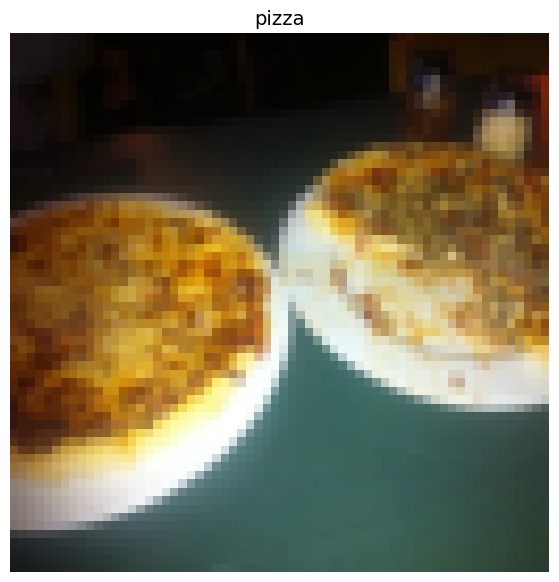

In [685]:
# Rearrange the order dimensions
img_permute = img.permute(1, 2, 0)

# print out diffent shapes
print(f"Original shape: {img.shape} -> [color_channels, height, width]")
print(f"Permuted shape: {img_permute.shape} -> [height, width, color_channels]")

# Plot the image
plt.figure(figsize=(10, 7))
plt.imshow(img_permute)
plt.axis("off")
plt.title(class_names[label], fontsize =14)

### 4.1 Turn loaded images into 'DataLoader'

A dataloader is going to help us turn our 'Dataset' into iterables and we can customise the batch_size, so our model can see batch_size images at a time

In [686]:
import os
os.cpu_count

<function posix.cpu_count()>

In [687]:
# Turn train and test datasets into DataLoader's
from torch.utils.data import DataLoader
BATCH_SIZE = 1
train_dataloader = DataLoader(dataset=train_data,
                              batch_size= BATCH_SIZE, # how many samples per batch?
                              num_workers=1, # how many subprocesses to use for data loading?
                              shuffle=True) # shuffle the data?

test_dataloader = DataLoader(dataset=test_data,
                             batch_size= BATCH_SIZE,
                             num_workers=1,
                             shuffle=False) # don't usually need to shuffle testing data
train_dataloader, test_dataloader

(<torch.utils.data.dataloader.DataLoader at 0x7af088fae350>,
 <torch.utils.data.dataloader.DataLoader at 0x7af088facb50>)

In [688]:
len(train_dataloader), len(test_dataloader)


(225, 75)

In [689]:
img, label = next(iter(train_dataloader))

# Batch size will now be 1, you can change the batch size if you lik
print(f"Image shape: {img.shape} -> [batch_size, color_channels, height, width]")
print(f"Label shape: {label.shape}")

Image shape: torch.Size([1, 3, 64, 64]) -> [batch_size, color_channels, height, width]
Label shape: torch.Size([1])


### 5 Option 2: Loading Image Data with a custom 'dataset'

1. Want to be able to load images form file
2. Want to be able to get class from the Dataset
3. Want to be able to get classes as dictionary from the dataset

Pros:
* Can create a 'Dataset' out of almost anything
* Not limited to PyTorch pre-built 'Dataset' functions

Cons:

* Even though you could create 'Datast' out of almost everythig, it does meatn i will work.

* Using a custom dataset often results in us wiritng more  code, which coudl be prone to errors or performance issues

All custom datasets in pytorch, often subclass - utils.data

In [690]:
import os
import pathlib
import torch

from PIL import Image
from torch.utils.data import Dataset
from torchvision import transforms
from typing import Tuple, Dict, List



In [691]:
# Instance of torchvision.datasets.ImageFolder()
train_data.classes, train_data.class_to_idx

(['pizza', 'steak', 'sushi'], {'pizza': 0, 'steak': 1, 'sushi': 2})

### 5.1 Creating a helper functiion to get class names

We want a function to:

1. Get the class names using os.scandir() to traverse a target directory ( ideally the directory is in standard image classification format).transforms
2. Raise an error if the class names aren't found (if this happens, there might be something wrong with the)
3. Turn the class names into a dict and a list and return them

In [692]:
# Setup path for target directotry
target_directory = train_dir
print(f"Target dir: {target_directory}")

# Get the class names form the target directory
class_names_found = sorted([entry.name for entry in list(os.scandir(target_directory))])
class_names_found

Target dir: data/pizza_steak_sushi/train


['pizza', 'steak', 'sushi']

In [693]:
def find_classes(directory: str) -> Tuple[List[str], Dict[str, int]]:
  """Finds the class folder names in a target directory."""
  # 1. Get the class names by scanning the target directory
  classes = sorted([entry.name for entry in os.scandir(directory) if entry.is_dir()])

  # 2. Raise an error if class names not found
  if not classes:
    raise FileNotFoundError(f"Couldn't find any classes in {directory}... please check your path.")

  # 3. Create a dictionary of index labels (e.g. {'pizza': 0, 'steak': 1, 'sushi': 2})
  class_to_idx = {class_name: i for i, class_name in enumerate(classes)}
  return classes, class_to_idx



In [694]:

find_classes(target_directory)

(['pizza', 'steak', 'sushi'], {'pizza': 0, 'steak': 1, 'sushi': 2})

### 5.2 Create a custom 'Dataset' to replicate 'Imagefolder'
To create our own custom dataset, we want to
1. Subclass 'torch.utils.data.Dataset'
2. Init our subclass with target directory(the directory we'd like to get data from) as well as a transform if we'd like to transform our data
3. Create several attributes:
* path -pahts of our images
* transform - the transorm we'd like to use
* classes - a list of the target classes
* class_to_idx - a dict of the target classes mapped to integer labels

4. Create a function to load images(), this function will open an image
5. Overwrite the __len()__ method to return the length of our dataset
6. Overwrite the __getitem()__ method to return a given sample when passed an index                                           

In [695]:
# Write a custom dataset class
from torch.utils.data import Dataset

# 1. Subclass torch.utils.data.Dataset
class ImageFolderCustom(Dataset):
  # 2. Initialize our custom dataset
  def __init__(self,
               targ_dir: str,
               transform=None):
    # 3. Create class attributes
    # Get all of the image paths
    self.paths = list(pathlib.Path(targ_dir).glob("*/*.jpg"))

    # Setup transform
    self.transform = transform
    # Create classes and class to idx attributes
    self.classes, self.class_to_idx = find_classes(targ_dir)

  # 4. Create a function to load images
  def load_image(self, index: int) -> Image.Image:
    "Opens an image via path and returns it"
    image_path = self.paths[index]
    return Image.open(image_path)

  # 5. Overwrite __len__()
  def __len__(self) -> int:
    "Returns the total number of samples"
    return len(self.paths)

  # 6. Overwrite __getitem__() method to return a particular sample
  def __getitem__(self, index: int) -> Tuple[torch.Tensor, int]:
    "Returns one sample of data, data and label (X, y)."
    img = self.load_image(index)
    class_name = self.paths[index].parent.name # expects path in format: data_folder/class_name/image.jpg
    class_idx = self.class_to_idx[class_name]

    # Transform if necessary
    if self.transform:
      return self.transform(img), class_idx # return data, label (X, y)
    else:
      return img, class_idx # return untransformed image and label

In [696]:
img, label

(tensor([[[[0.0627, 0.0588, 0.0588,  ..., 0.0863, 0.0902, 0.0863],
           [0.0706, 0.0706, 0.0784,  ..., 0.0902, 0.0863, 0.0863],
           [0.0784, 0.1098, 0.2863,  ..., 0.0824, 0.0824, 0.0863],
           ...,
           [0.8118, 0.8471, 0.8588,  ..., 0.7647, 0.7686, 0.7725],
           [0.5294, 0.5882, 0.6706,  ..., 0.7137, 0.6627, 0.5961],
           [0.3882, 0.3765, 0.4039,  ..., 0.3882, 0.2902, 0.2235]],
 
          [[0.0549, 0.0510, 0.0549,  ..., 0.0863, 0.0902, 0.0863],
           [0.0627, 0.0627, 0.0784,  ..., 0.0902, 0.0863, 0.0863],
           [0.0667, 0.0980, 0.2863,  ..., 0.0824, 0.0824, 0.0863],
           ...,
           [0.4471, 0.4039, 0.3608,  ..., 0.2235, 0.2235, 0.2314],
           [0.3725, 0.4118, 0.4549,  ..., 0.2196, 0.2118, 0.2039],
           [0.2627, 0.2627, 0.2863,  ..., 0.1333, 0.1137, 0.1059]],
 
          [[0.0667, 0.0627, 0.0706,  ..., 0.1176, 0.1216, 0.1255],
           [0.0745, 0.0745, 0.0863,  ..., 0.1216, 0.1176, 0.1255],
           [0.0824, 0.10

In [697]:
# Instantiate custom datasets
train_data_custom = ImageFolderCustom(targ_dir=train_dir,
                                      transform=data_transform)

test_data_custom = ImageFolderCustom(targ_dir=test_dir,
                                     transform=data_transform)

# Compare lengths and class structures
print(f"Custom train length: {len(train_data_custom)} | Custom test length: {len(test_data_custom)}")
print(f"Classes found: {train_data_custom.classes}")
print(f"Class to index mapping: {train_data_custom.class_to_idx}")

Custom train length: 225 | Custom test length: 75
Classes found: ['pizza', 'steak', 'sushi']
Class to index mapping: {'pizza': 0, 'steak': 1, 'sushi': 2}


In [698]:
# Create a transform
from torchvision import transforms
data_transform = transforms.Compose([
    transforms.Resize(size=(64, 64)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.ToTensor()
])

test_transforms = transforms.Compose([
    transforms.Resize(size=(64, 64)),
    transforms.ToTensor()
])


In [699]:
# Test out ImageFolderCustom
train_data_custom = ImageFolderCustom(targ_dir=train_dir,
                                      transform=data_transform)

test_data_custom = ImageFolderCustom(targ_dir=test_dir,
                                     transform=test_transforms)

#

In [700]:
train_data_custom, test_data_custom

(<__main__.ImageFolderCustom at 0x7af081782990>,
 <__main__.ImageFolderCustom at 0x7af0a7f0b5c0>)

In [701]:
len(train_data), len(train_data_custom)

(225, 225)

In [702]:
len(test_data), len(test_data_custom)

(75, 75)

In [703]:
train_data_custom.classes

['pizza', 'steak', 'sushi']

In [704]:
# Check for equality between original  Imagefolder Dataset and  Imagefoldercustom dataset
print(train_data_custom.classes==train_data.classes)
print(test_data_custom.classes==test_data.classes)


True
True


### 5.3 Create a function to display random images

1. Take in a 'Dataset' and a number of other parameters such as class names and how many images to visualize
2. To prevent the display getting out of hand, let's cap the number of images to see at 10.
3. Set the random seed for reproducibility
4. Get a list of random sample indexes from the target dataset.
5. Setup a matplotlib plot
6. Loop through the random sample images and plot them with matplotlib
7. Make sure the dimensions of our images lines with matplotlib(HWC)

In [705]:
# Create a function to take in a dataset
def display_random_images(dataset: torch.utils.data.Dataset,
                          classes: List[str] = None,
                          n: int = 10,
                          display_shape: bool = True,
                          seed: int = None):

  # 2. Adjust display if n is too high
  if n > 10:
    n = 10
    display_shape = False
    print(f"for display, purposes, n shouldn't be larger than 10, setting to 10 and removing shape display. ")

  # 3.Set the seed
  if seed:
    random.seed(seed)

  # 4. Get random sample indexes
  random_sample_idx = random.sample(range(len(dataset)), k=n)

  # 5. Setup Plot
  plt.figure(figsize=(16, 8))

  # 6. Loop through random indexes and plot them with matplotlib
  for i, targ_sample in enumerate(random_sample_idx):
    targ_image, targ_label = dataset[targ_sample]

    # 7. Adjust tensor dimensions for plotting
    targ_image_adjust = targ_image.permute(1, 2, 0) # [color_channels, height, width] -> [height, width, color_channels]
    # plot adjusted samples
    plt.subplot(1, n, i+1)
    plt.imshow(targ_image_adjust)
    plt.axis("off")
    if classes:
      title = f"Class: {classes[targ_label]}"
      if display_shape:
        title = title + f"\nShape: {targ_image.shape}"
      plt.title(title)

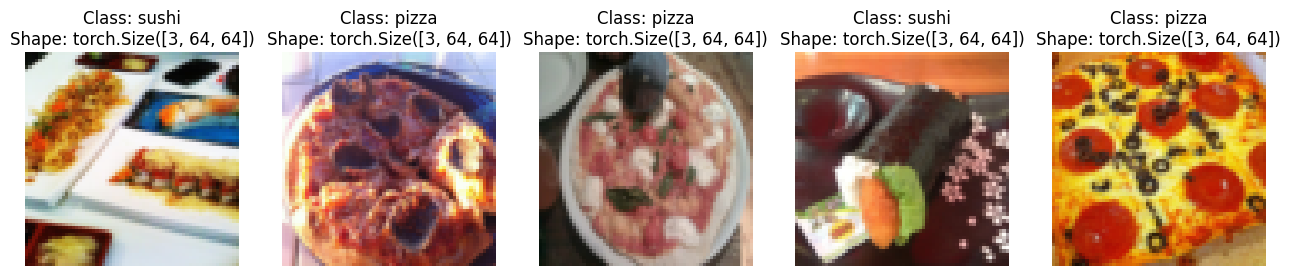

In [706]:
# Make sure random is imported and call the display function
import random

display_random_images(dataset=train_data,
                      classes=train_data.classes,
                      n=5,
                      display_shape=True,
                      seed=42)

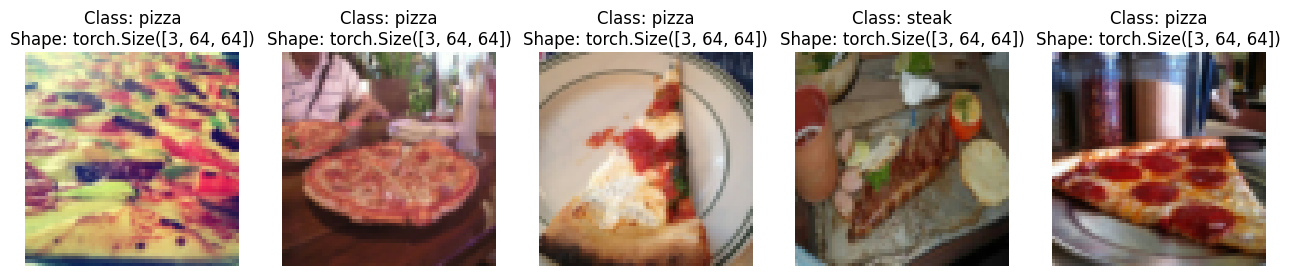

In [707]:
# Display random images from the ImagefolderCustom Dataset
display_random_images(train_data_custom,
                      n=5,
                      classes = class_names,
                      seed=None)

### 5.4 Turn custom loaded images into DataLoader's

In [708]:
from  torch.utils.data import DataLoader
BATCH_SIZE = 32

train_dataloader_custom = DataLoader(dataset=train_data_custom,
                                      batch_size=BATCH_SIZE,
                                      num_workers=1,
                                      shuffle=True)

test_dataloader_custom = DataLoader(dataset=test_data_custom,
                                     batch_size=BATCH_SIZE,
                                     num_workers=1,
                                     shuffle=False)
train_dataloader_custom, test_dataloader_custom


(<torch.utils.data.dataloader.DataLoader at 0x7af088fad050>,
 <torch.utils.data.dataloader.DataLoader at 0x7af088fadb50>)

In [709]:
# Get image and label from customer dataloader
img_custom,  label_custom = next(iter(train_dataloader_custom))

# Print out the shapes
img_custom.shape, label_custom.shape

(torch.Size([32, 3, 64, 64]), torch.Size([32]))

## 6. Other forms of transfoms (data augmentation)

Data augmentation is the process of artificaially adding diversity to your training data.

In the case of image data, this may mean applying vvarious image transformations to the training images.
This practice hopefully results in a model that's more generalizable to unseen data

Let's take a look at one particular type of data augmentation used to train PyTorch vision models to state of the art levels...

In [710]:
# Let's look at tivial augment
from torchvision import transforms

train_transform = transforms.Compose([
    transforms.Resize(size=(224, 224)),
    transforms.TrivialAugmentWide(num_magnitude_bins=31),
    transforms.ToTensor()
])


In [711]:
import os
import requests
import zipfile
from pathlib import Path

data_path = Path("data/")
image_path = data_path / "pizza_steak_sushi"

# Automatically re-download if the data directory was wiped from the Colab instance
if not image_path.is_dir():
    print("Data not found! Re-downloading dataset...")
    image_path.mkdir(parents=True, exist_ok=True)
    zip_filepath = data_path / "pizza_steak_sushi.zip"

    # Download
    with open(zip_filepath, "wb") as f:
        request = requests.get("https://github.com/mrdbourke/pytorch-deep-learning/raw/main/data/pizza_steak_sushi.zip")
        f.write(request.content)

    # Unzip
    with zipfile.ZipFile(zip_filepath, "r") as zip_ref:
        zip_ref.extractall(image_path)
    print("Redownload complete!")

# Get all image paths recursively
image_path_list = list(image_path.glob("**/*.jpg"))
print(f"Total images found: {len(image_path_list)}")
image_path_list[:10]

Total images found: 300


[PosixPath('data/pizza_steak_sushi/test/pizza/3475871.jpg'),
 PosixPath('data/pizza_steak_sushi/test/pizza/540882.jpg'),
 PosixPath('data/pizza_steak_sushi/test/pizza/2111981.jpg'),
 PosixPath('data/pizza_steak_sushi/test/pizza/2236338.jpg'),
 PosixPath('data/pizza_steak_sushi/test/pizza/2508636.jpg'),
 PosixPath('data/pizza_steak_sushi/test/pizza/2218680.jpg'),
 PosixPath('data/pizza_steak_sushi/test/pizza/1152100.jpg'),
 PosixPath('data/pizza_steak_sushi/test/pizza/2019408.jpg'),
 PosixPath('data/pizza_steak_sushi/test/pizza/930553.jpg'),
 PosixPath('data/pizza_steak_sushi/test/pizza/971934.jpg')]

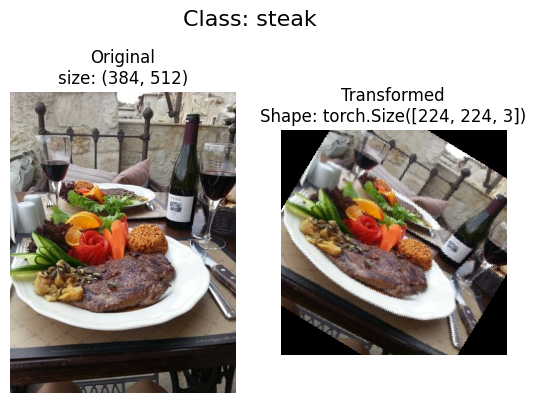

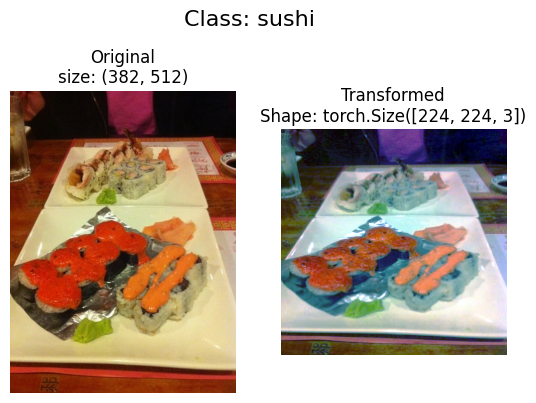

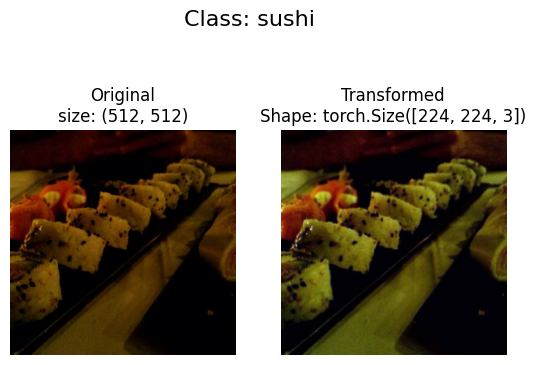

In [712]:
# Plot random transformed images using TrivialAugment
plot_transformed_images(
    image_paths=image_path_list,
    transform=train_transform,
    n=3,
    seed=None
)

### 7. Model 0: TinyVGG without data augmentation

Let's replicate TinyVGG architecture from CNN Explainer website


### 7.1 Creating transforms and loadind data for Model 0

In [713]:
# Create simple transfom
simple_transform = transforms.Compose([
    transforms.Resize(size=(64, 64)),
    transforms.ToTensor()
])

In [714]:
# 1. Load and transform data
from torchvision import datasets
train_data_simple = datasets.ImageFolder(
    root=train_dir,
    transform=simple_transform,
    target_transform=None
)

test_data_simple = datasets.ImageFolder(
    root=test_dir,
    transform=simple_transform,
    target_transform=None

)
# 2. Turn the datasets into DataLoaders
import os
from torch.utils.data import DataLoader

# Setup batch size and number of works
BATCH_SIZE = 32
NUM_WORKERS = os.cpu_count()

# Create DataLoader's
train_dataloader_simple = DataLoader(dataset= train_data_simple,
                                     batch_size=BATCH_SIZE,
                                     num_workers=NUM_WORKERS,
                                     shuffle=True)



test_dataloader_simple = DataLoader(dataset=test_data_simple,
                                    batch_size=BATCH_SIZE,
                                    num_workers=NUM_WORKERS,
                                    shuffle=False)





## 7.2 Create TinyVGG Models

In [715]:
class TinyVGG(nn.Module):
  """
  Model architecture copying TinyVGG from CNN Explainer
  """
  def __init__(self, input_shape: int, hidden_units: int, output_shape: int) -> None:
    super().__init__()
    self.conv_block_1 = nn.Sequential(
        nn.Conv2d(in_channels=input_shape,
                  out_channels=hidden_units,
                  kernel_size=3,
                  stride=1,
                  padding=1),
        nn.ReLU(),
        nn.Conv2d(in_channels=hidden_units,
                  out_channels=hidden_units,
                  kernel_size=3,
                  stride=1,
                  padding=1),
        nn.ReLU(),
        nn.MaxPool2d(kernel_size=2,
                     stride=2)
    )
    self.conv_block_2 = nn.Sequential(
        nn.Conv2d(in_channels=hidden_units,
                  out_channels=hidden_units,
                  kernel_size=3,
                  stride=1,
                  padding=1),
        nn.ReLU(),
        nn.Conv2d(in_channels=hidden_units,
                  out_channels=hidden_units,
                  kernel_size=3,
                  stride=1,
                  padding=1),
        nn.ReLU(),
        nn.MaxPool2d(kernel_size=2,
                     stride=2)
    )
    self.classifier = nn.Sequential(
        nn.Flatten(),
        # Our input images are (3, 64, 64).
        # After 2 MaxPool2d pooling layers of stride 2, the spatial dimension goes from 64 -> 32 -> 16.
        nn.Linear(in_features=hidden_units * 16 * 16,
                  out_features=output_shape)
    )

  def forward(self, x: torch.Tensor):
    x = self.conv_block_1(x)
    x = self.conv_block_2(x)
    x = self.classifier(x)
    return x
    #return self.classifier(self.conv_block_2(self.conv_block_1(x))) #benefits from operator fusion

In [716]:
torch.manual_seed(42)
model_0 = TinyVGG(input_shape=3,
                  hidden_units=10,
                  output_shape=len(train_data.classes))
model_0

TinyVGG(
  (conv_block_1): Sequential(
    (0): Conv2d(3, 10, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): Conv2d(10, 10, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (3): ReLU()
    (4): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (conv_block_2): Sequential(
    (0): Conv2d(10, 10, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): Conv2d(10, 10, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (3): ReLU()
    (4): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=2560, out_features=3, bias=True)
  )
)

### 7.3 Try a forward pass on a single image(to test the model)

In [717]:
# Get a single image batch
image_batch, label_batch = next(iter(train_dataloader_simple))
image_batch.shape, label_batch.shape

(torch.Size([32, 3, 64, 64]), torch.Size([32]))

In [718]:
# Try a forward pass
model_0(image_batch.to(device))

tensor([[0.0578, 0.0634, 0.0351],
        [0.0657, 0.0650, 0.0398],
        [0.0702, 0.0678, 0.0412],
        [0.0687, 0.0646, 0.0417],
        [0.0625, 0.0613, 0.0355],
        [0.0587, 0.0595, 0.0358],
        [0.0634, 0.0637, 0.0376],
        [0.0653, 0.0615, 0.0376],
        [0.0678, 0.0621, 0.0349],
        [0.0620, 0.0599, 0.0371],
        [0.0607, 0.0628, 0.0387],
        [0.0638, 0.0589, 0.0352],
        [0.0658, 0.0611, 0.0369],
        [0.0703, 0.0689, 0.0330],
        [0.0557, 0.0571, 0.0356],
        [0.0632, 0.0642, 0.0388],
        [0.0639, 0.0616, 0.0375],
        [0.0605, 0.0600, 0.0374],
        [0.0623, 0.0627, 0.0368],
        [0.0740, 0.0676, 0.0400],
        [0.0621, 0.0613, 0.0361],
        [0.0632, 0.0599, 0.0366],
        [0.0662, 0.0627, 0.0334],
        [0.0637, 0.0622, 0.0394],
        [0.0670, 0.0666, 0.0363],
        [0.0650, 0.0601, 0.0405],
        [0.0639, 0.0597, 0.0395],
        [0.0733, 0.0687, 0.0412],
        [0.0697, 0.0631, 0.0402],
        [0.062

### 7.4 Use torchinfo to get an idea of the shapes going through our model

In [719]:
# Install torchinfo, import if it's available
try:
  import torchinfo
except:
  !pip install torchinfo
  import torchinfo

from torchinfo import summary
summary(model_0, input_size=[1, 3, 64, 64])

Layer (type:depth-idx)                   Output Shape              Param #
TinyVGG                                  [1, 3]                    --
├─Sequential: 1-1                        [1, 10, 32, 32]           --
│    └─Conv2d: 2-1                       [1, 10, 64, 64]           280
│    └─ReLU: 2-2                         [1, 10, 64, 64]           --
│    └─Conv2d: 2-3                       [1, 10, 64, 64]           910
│    └─ReLU: 2-4                         [1, 10, 64, 64]           --
│    └─MaxPool2d: 2-5                    [1, 10, 32, 32]           --
├─Sequential: 1-2                        [1, 10, 16, 16]           --
│    └─Conv2d: 2-6                       [1, 10, 32, 32]           910
│    └─ReLU: 2-7                         [1, 10, 32, 32]           --
│    └─Conv2d: 2-8                       [1, 10, 32, 32]           910
│    └─ReLU: 2-9                         [1, 10, 32, 32]           --
│    └─MaxPool2d: 2-10                   [1, 10, 16, 16]           --
├─Sequentia

### 7.5 Create train and test loops functions

* 'train_step() - takes in a model and dataloader and trains the model on the dataloader

* test_step() - takes in a model and dataloader and evaluates the model on the dataloader

In [720]:
# Create train_step()
def train_step(model: torch.nn.Module,
               dataloader: torch.utils.data.DataLoader,
               loss_fn: torch.nn.Module,
               optimizer: torch.optim.Optimizer,
               device=device):

  # Put the model in train mode
  model.train*()

  # Setup train loss and train accuracy values
  train_loss, train_acc = 0, 0

  # Loop through data loader data batches
  for batch, (X, y) in enumerate(dataloader):
    # Send data to the target device
    X, y = X.to(device), y.to(device)

    #1. forward pass
    y_pred = model(X)

    #2. Calculate the loss
    loss = loss_fn(y_pred, y)
    train_loss += loss.item()

    #3. Optimizer zero grad
    optimizer.zero_grad()

    #4. Loss backward
    loss.backward()

    #5. Optimizer step
    optimizer.step()

    # Calculate accuracy metric
    y_pred_class = torch.argmax(torch.softmax(y_pred, dim=1), dim=1)
    train_acc += (y_pred_class == y).sum().item()/len(y_pred)

    # Adjust metrics to get average loss and accuracy per batch

    train_loss = train_loss / len(dataloader)
    train_acc = train_acc / len(dataloader)
    return train_loss, train_acc


In [721]:
from IPython.testing import test
# Create  a test step
def test_step(model: torch.nn.Module,
              dataloader: torch.utils.data.DataLoader,
              loss_fn: torch.nn.Module,
              device: torch.device=device):

  # put model in eval mode
  model.eval()

  # Setup test loss and test accuracy values
  test_loss, test_acc = 0, 0

  # Turn on inference mode
  with torch.inference_mode():
    # Loop through DataLoader batches
    for batch, (X, y) in enumerate(dataloader):
      # Send data to the target device
      X, y = X.to(device), y.to(device)

      # 1. Forward pass
      test_pred_logits = model(X)

      # 2. Calculate the loss
      loss = loss_fn(test_pred_logits, y)
      test_loss += loss.item()

      # Calculate the accuracy
      test_pred_labels = test_pred_logits.argmax(dim=1)
      test_acc += ((test_pred_labels == y).sum().item()/len(test_pred_labels))

  # Adjust metrics to get average loss and accuracy per batch

  test_data = test_loss / len(dataloader)
  test_acc = test_acc / len(dataloader)
  return test_data, test_acc

### 7.6 Creating a train() function to combine train_step() and test_step()

In [722]:
from tqdm.auto import tqdm

# 1. Create a train function that takes in various model parameters + optimizer +
def train(model: torch.nn.Module,
          train_dataloader: torch.utils.data.DataLoader,
          optimizer: torch.optim.Optimizer,
          loss_fn: torch.nn.Module = nn.CrossEntropyLoss(),
          epochs: int = 5,
          device: torch.device = device):
  # 2. Creat empty resulst dictionary
  results = {"train_loss": [],
             "train_acc": [],
             "test_loss": [],
             "test_acc": []}
  # 3. Loop through training and testing steps for a number of epochs
  for epoch in tqdm(range(epochs)):
    train_loss, train_acc = train_step(model=model,
                                       dataloader=train_dataloader,
                                       loss_fn=loss_fn,
                                       optimizer=optimizer,
                                       device=device)
    test_loss, test_acc = test_step(model=model,
                                    dataloader=test_dataloader,
                                    loss_fn=loss_fn,
                                    device=device)

    # 4. Print out what's happening
    print(f"Epoch: {epoch} | Train loss: {train_loss:.4f} | Train acc: {train_acc:.4f} | Test loss: {test_loss:.4f} | Test acc: {test_acc:.4f}")

    # 5. Update results dictionary
    results["train_loss"].append(train_loss)
    results["train_acc"].append(train_acc)
    results["test_loss"].append(test_loss)
    results["test_acc"].append(test_acc)

    # 6. Return the filled results at the end of the epochs
    return results


### 7.7  Train and evaluate model 0

In [723]:
def train(model: torch.nn.Module,
          train_dataloader: torch.utils.data.DataLoader,
          test_dataloader: torch.utils.data.DataLoader, # Add this line
          optimizer: torch.optim.Optimizer,
          loss_fn: torch.nn.Module = nn.CrossEntropyLoss(),
          epochs: int = 5,
          device: torch.device = device):

    # ... (keep your existing dictionary setup) ...

    for epoch in tqdm(range(epochs)):
        train_loss, train_acc = train_step(model=model,
                                           dataloader=train_dataloader,
                                           loss_fn=loss_fn,
                                           optimizer=optimizer,
                                           device=device)

        # This will now correctly use the test_dataloader you passed in
        test_loss, test_acc = test_step(model=model,
                                        dataloader=test_dataloader,
                                        loss_fn=loss_fn,
                                        device=device)

        # ... (keep the rest of your print statements and dictionary appends) ...

In [724]:
from tqdm.auto import tqdm

# 1. Create a train function that takes in various model parameters + optimizer
def train(model: torch.nn.Module,
          train_dataloader: torch.utils.data.DataLoader,
          test_dataloader: torch.utils.data.DataLoader, # ADDED THIS LINE
          optimizer: torch.optim.Optimizer,
          loss_fn: torch.nn.Module = nn.CrossEntropyLoss(),
          epochs: int = 5,
          device: torch.device = device):

    # 2. Create empty results dictionary
    results = {"train_loss": [],
               "train_acc": [],
               "test_loss": [],
               "test_acc": []}

    # 3. Loop through training and testing steps for a number of epochs
    for epoch in tqdm(range(epochs)):
        train_loss, train_acc = train_step(model=model,
                                           dataloader=train_dataloader,
                                           loss_fn=loss_fn,
                                           optimizer=optimizer,
                                           device=device)

        test_loss, test_acc = test_step(model=model,
                                        dataloader=test_dataloader,
                                        loss_fn=loss_fn,
                                        device=device)

        # 4. Print out what's happening
        print(f"Epoch: {epoch} | Train loss: {train_loss:.4f} | Train acc: {train_acc:.4f} | Test loss: {test_loss:.4f} | Test acc: {test_acc:.4f}")

        # 5. Update results dictionary
        results["train_loss"].append(train_loss)
        results["train_acc"].append(train_acc)
        results["test_loss"].append(test_loss)
        results["test_acc"].append(test_acc)

    # 6. Return the filled results at the end of the epochs
    return results

In [725]:
# Create train_step()
def train_step(model: torch.nn.Module,
               dataloader: torch.utils.data.DataLoader,
               loss_fn: torch.nn.Module,
               optimizer: torch.optim.Optimizer,
               device=device):

    # Put the model in train mode (REMOVED THE ASTERISK HERE)
    model.train()

    # Setup train loss and train accuracy values
    train_loss, train_acc = 0, 0

    # Loop through data loader data batches
    for batch, (X, y) in enumerate(dataloader):
        # Send data to the target device
        X, y = X.to(device), y.to(device)

        # 1. forward pass
        y_pred = model(X)

        # 2. Calculate the loss
        loss = loss_fn(y_pred, y)
        train_loss += loss.item()

        # 3. Optimizer zero grad
        optimizer.zero_grad()

        # 4. Loss backward
        loss.backward()

        # 5. Optimizer step
        optimizer.step()

        # Calculate accuracy metric
        y_pred_class = torch.argmax(torch.softmax(y_pred, dim=1), dim=1)
        train_acc += (y_pred_class == y).sum().item()/len(y_pred)

    # Adjust metrics to get average loss and accuracy per batch
    train_loss = train_loss / len(dataloader)
    train_acc = train_acc / len(dataloader)

    return train_loss, train_acc

In [726]:
model_0_results

{'train_loss': [1.099464789032936,
  1.0954465568065643,
  1.0981492400169373,
  1.092481106519699,
  1.0950559079647064],
 'train_acc': [0.2890625, 0.453125, 0.29296875, 0.4140625, 0.29296875],
 'test_loss': [1.104337493578593,
  1.112195094426473,
  1.120409607887268,
  1.1251165469487507,
  1.1323232253392537],
 'test_acc': [0.2604166666666667,
  0.19791666666666666,
  0.19791666666666666,
  0.19791666666666666,
  0.19791666666666666]}

### 7.8 Plot the loss curves of Model 0
A loss curve is a way of tracking your model's progress over time.
A good guide for differnt loss curves can be seen here:


# Get the model_0_results keys
model_0_results.keys()

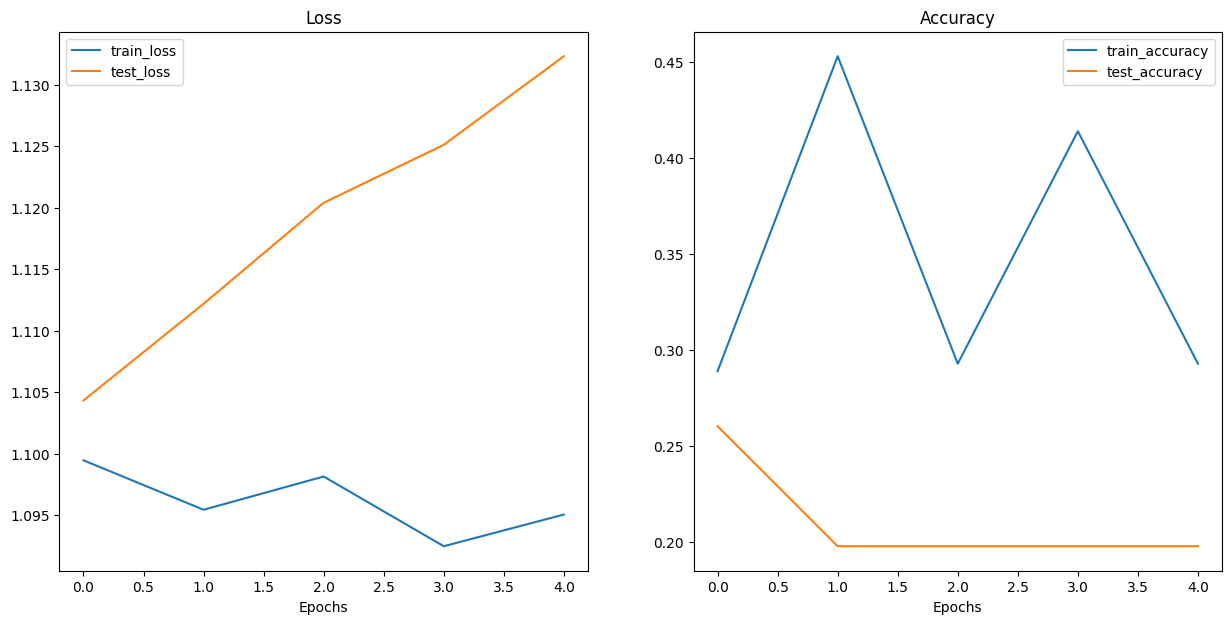

In [727]:
from typing import Dict, List
import matplotlib.pyplot as plt

def plot_loss_curves(results: Dict[str, List[float]]):
    """Plots training curves of a results dictionary."""

    # Get the loss values of the results dictionary (training and test)
    loss = results["train_loss"]
    test_loss = results["test_loss"]

    # Get the accuracy values of the results dictionary (training and test)
    accuracy = results["train_acc"]
    test_accuracy = results["test_acc"]

    # Figure out how many epochs there were
    epochs = range(len(results["train_loss"]))

    # Setup a plot
    plt.figure(figsize=(15, 7))

    # Plot the loss
    plt.subplot(1, 2, 1)
    plt.plot(epochs, loss, label="train_loss")
    plt.plot(epochs, test_loss, label="test_loss")
    plt.title("Loss")
    plt.xlabel("Epochs")
    plt.legend()

    # Plot the accuracy
    plt.subplot(1, 2, 2)
    plt.plot(epochs, accuracy, label="train_accuracy")
    plt.plot(epochs, test_accuracy, label="test_accuracy")
    plt.title("Accuracy")
    plt.xlabel("Epochs")
    plt.legend()

# Call the function to actually plot the results
plot_loss_curves(model_0_results)

### 8. What should an ideal loss curve look like?

A loss curve is one of the most helpful ways to trouble shoot a model

### 9. Model 1: TinyVGG with Data Augmentation
Now let's try another modelling experiment this time using the same model as before with some data augmentation.                                                             

### 9.1 Create transorm with data augmentation

In [728]:
# Create training transform with TrivialAugment
from torchvision import transforms
train_transforms_trivial = transforms.Compose([transforms.Resize(size=(64, 64)),
                                               transforms.TrivialAugmentWide(num_magnitude_bins=31),
                                               transforms.ToTensor()

                                               ])
test_transform_simple = transforms.Compose([transforms.Resize(size=(64, 64)),
                                            transforms.ToTensor()])

### 9.2 Create train and test Dataset's and DataLoader's with data augmentation

In [729]:
# Turn image folders into Datasets
from torchvision import datasets
train_data_augmented = datasets.ImageFolder(root=train_dir,
                                            transform=train_transforms_trivial)

test_data_simple = datasets.ImageFolder(root=test_dir,
                                        transform=test_transform_simple)

In [730]:
# Turn our Datasets into DataLoaders
import os
from torch.utils.data import DataLoader

BATCH_SIZE = 32
NUM_WORKERS = os.cpu_count()

torch.manual_seed(42)

train_dataloader_augmented = DataLoader(
    dataset=train_data_augmented,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS # Fixed typo here
)

test_dataloader_simple = DataLoader( # Fixed typo here
    dataset=test_data_simple,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS
)

### 9.3 Construct and train model 1

This time we'll be using the same model architecture except this time we've augmented the training data.

In [731]:
# Create model_1 and send it to the target device
torch.manual_seed(42)
model_1 = TinyVGG(input_shape=3,
                  hidden_units=10,
                  output_shape=len(train_data_augmented.classes)).to(device)
model_1

TinyVGG(
  (conv_block_1): Sequential(
    (0): Conv2d(3, 10, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): Conv2d(10, 10, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (3): ReLU()
    (4): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (conv_block_2): Sequential(
    (0): Conv2d(10, 10, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): Conv2d(10, 10, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (3): ReLU()
    (4): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=2560, out_features=3, bias=True)
  )
)

Wonderful! Now we've a a model and datalodader, let's create a loss function and an optimizer and call upon our trained data to evaluate our model

In [732]:
# Set random seeds
torch.manual_seed(42)
torch.cuda.manual_seed(42)

# Set the number of epochs
NUM_EPOCHS = 5

# setup loss function
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.SGD(params=model_1.parameters(),
                            lr=0.001)

# Start the timer
from timeit import default_timer as timer
start_time = timer()

# Train model_1
model_1_results = train(model=model_1,
                        train_dataloader=train_dataloader_augmented,
                        test_dataloader=test_dataloader_simple,
                        optimizer=optimizer,
                        loss_fn=loss_fn,
                        epochs=NUM_EPOCHS,
                        device=device)
# End the timer and print out how long it took
end_time = timer()
print(f"Total training time: {end_time-start_time:.3f} seconds")

  0%|          | 0/5 [00:00<?, ?it/s]

Epoch: 0 | Train loss: 1.0978 | Train acc: 0.2578 | Test loss: 1.1049 | Test acc: 0.2604
Epoch: 1 | Train loss: 1.0965 | Train acc: 0.4258 | Test loss: 1.1060 | Test acc: 0.2604
Epoch: 2 | Train loss: 1.0946 | Train acc: 0.4258 | Test loss: 1.1072 | Test acc: 0.2604
Epoch: 3 | Train loss: 1.0988 | Train acc: 0.3047 | Test loss: 1.1088 | Test acc: 0.2604
Epoch: 4 | Train loss: 1.0943 | Train acc: 0.4258 | Test loss: 1.1100 | Test acc: 0.2604
Total training time: 12.272 seconds


In [733]:
model_1_results

{'train_loss': [1.0978480130434036,
  1.0964550226926804,
  1.0946399122476578,
  1.0988470613956451,
  1.094311311841011],
 'train_acc': [0.2578125, 0.42578125, 0.42578125, 0.3046875, 0.42578125],
 'test_loss': [1.1048564513524373,
  1.1059714555740356,
  1.1071998278299968,
  1.1088494857152302,
  1.109961986541748],
 'test_acc': [0.2604166666666667,
  0.2604166666666667,
  0.2604166666666667,
  0.2604166666666667,
  0.2604166666666667]}

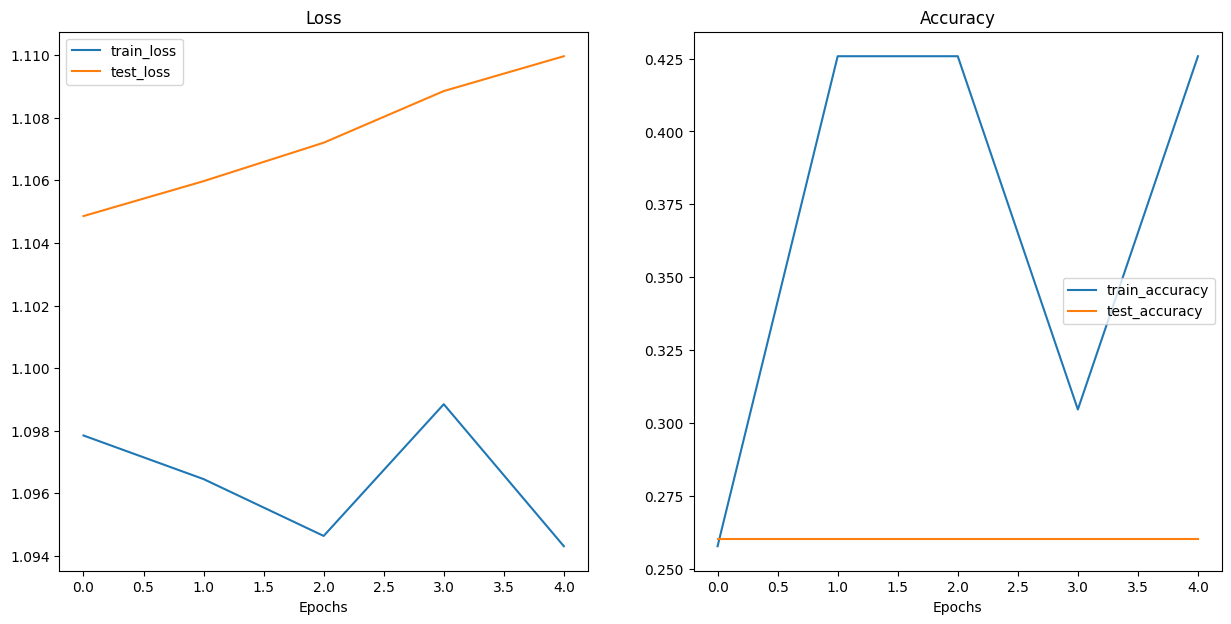

In [734]:
plot_loss_curves(model_1_results)

### 10. compare model results

After evaluating our modelling experiments on their own, it's important to compare them to each other
There's a few different ways to do this:

1. Hard coding (what we're doing)

2. PyTorch + Tensorboard


3. Weights & Biases
4. MLFlow

In [735]:
import pandas as pd
model_0_df = pd.DataFrame(model_0_results)
model_1_df = pd.DataFrame(model_1_results)
model_0_df

,train_loss,train_acc,test_loss,test_acc
0,1.099465,0.289062,1.104337,0.260417
1,1.095447,0.453125,1.112195,0.197917
2,1.098149,0.292969,1.120410,0.197917
3,1.092481,0.414062,1.125117,0.197917
4,1.095056,0.292969,1.132323,0.197917


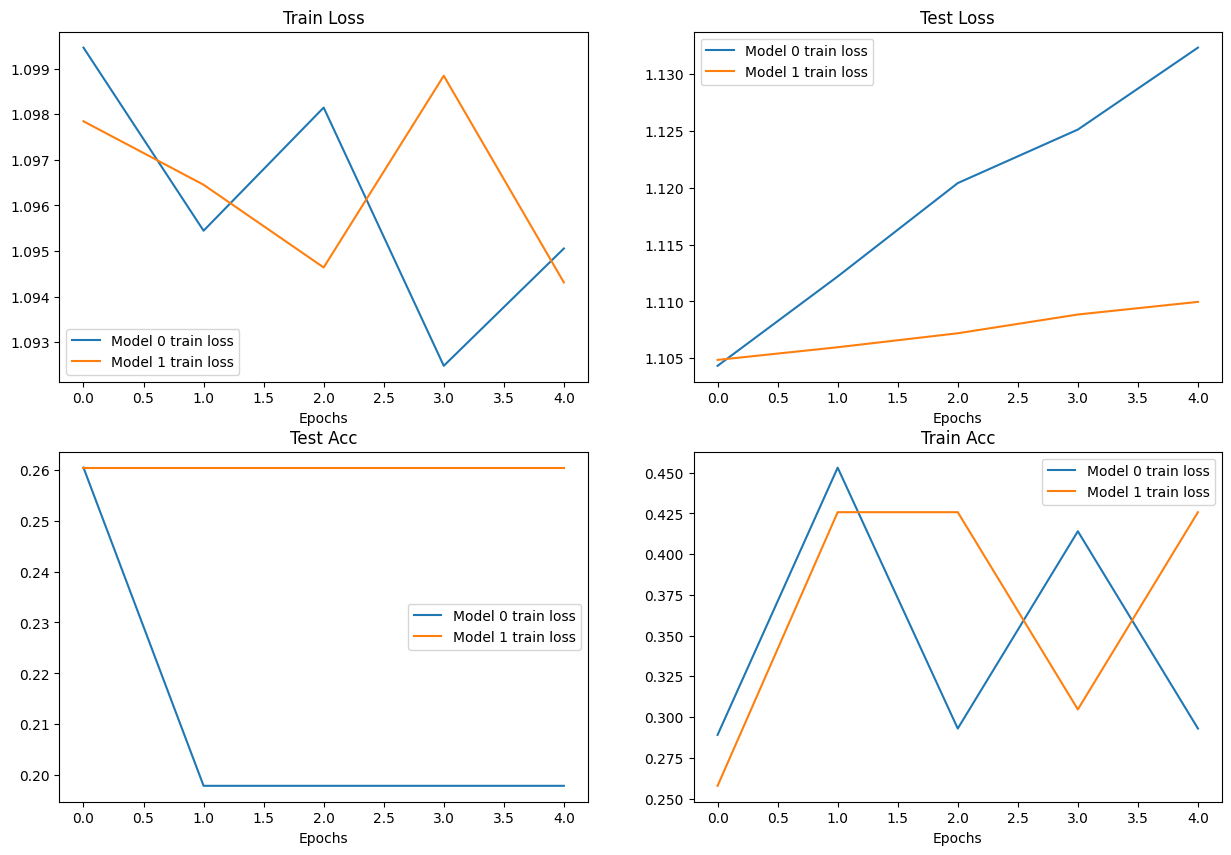

In [736]:
# Setup a plot
plt.figure(figsize=(15, 10))

# Get number of epochs
epochs = range(len(model_0_df))

# Plot test loss
plt.subplot(2, 2, 1)
plt.plot(epochs, model_0_df["train_loss"], label="Model 0 train loss")
plt.plot(epochs, model_1_df["train_loss"], label="Model 1 train loss")
plt.title("Train Loss")
plt.xlabel("Epochs")
plt.legend()


# Plot test loss
plt.subplot(2, 2, 2)
plt.plot(epochs, model_0_df["test_loss"], label="Model 0 train loss")
plt.plot(epochs, model_1_df["test_loss"], label="Model 1 train loss")
plt.title("Test Loss")
plt.xlabel("Epochs")
plt.legend()


# Plot test
plt.subplot(2, 2, 3)
plt.plot(epochs, model_0_df["test_acc"], label="Model 0 train loss")
plt.plot(epochs, model_1_df["test_acc"], label="Model 1 train loss")
plt.title("Test Acc")
plt.xlabel("Epochs")
plt.legend()

# Plot test loss
plt.subplot(2, 2, 4)
plt.plot(epochs, model_0_df["train_acc"], label="Model 0 train loss")
plt.plot(epochs, model_1_df["train_acc"], label="Model 1 train loss")
plt.title("Train Acc")
plt.xlabel("Epochs")
plt.legend()



### 11. Making a prediction on a custom image

Although we've trained model on cusom data... how do you make a prediction on a sample/image that's not in every dataset.

In [737]:
# Dpwnload custom image
import requests

# Setup custom image path
custom_image_path = data_path / "04-pizza-dad.jpeg"

# Download the image if it doesn't exist yet.
if not custom_image_path.is_file():
  with open (custom_image_path, "wb") as f:
      # when downloading from GitHub, need to use the "raw" file link
    request = requests.get("https://raw.githubusercontent.com/mrdbourke/pytorch-deep-learning/main/data/pizza_dad.jpeg")
    print(f"Downloading {request} to {custom_image_path}...")
    f.write(request.content)
else:
    print(f"{custom_image_path} already exists")


data/04-pizza-dad.jpeg already exists


### 11.1 Loading in a custom image with PyTorch

We have to make sure our custom image is in the same format as the dat our model was trained on
* In tensor form  with datatype (torch.float32)
* Of shape 64x64x3 (height, width, color channels)
* on the right device

In [738]:
custom_image_path

PosixPath('data/04-pizza-dad.jpeg')

Custom image tensor:
 tensor([[[154, 173, 181,  ...,  21,  18,  14],
         [146, 165, 181,  ...,  21,  18,  15],
         [124, 146, 172,  ...,  18,  17,  15],
         ...,
         [ 72,  59,  45,  ..., 152, 150, 148],
         [ 64,  55,  41,  ..., 150, 147, 144],
         [ 64,  60,  46,  ..., 149, 146, 143]],

        [[171, 190, 193,  ...,  22,  19,  15],
         [163, 182, 193,  ...,  22,  19,  16],
         [141, 163, 184,  ...,  19,  18,  16],
         ...,
         [ 55,  42,  28,  ..., 107, 104, 103],
         [ 47,  38,  24,  ..., 108, 104, 102],
         [ 47,  43,  29,  ..., 107, 104, 101]],

        [[119, 138, 147,  ...,  17,  14,  10],
         [111, 130, 145,  ...,  17,  14,  11],
         [ 87, 111, 136,  ...,  14,  13,  11],
         ...,
         [ 35,  22,   8,  ...,  52,  52,  48],
         [ 27,  18,   4,  ...,  50,  49,  44],
         [ 27,  23,   9,  ...,  49,  46,  43]]], dtype=torch.uint8)
Custom image shape:
 torch.Size([3, 4032, 3024])
Custom image dat

(np.float64(-0.5), np.float64(3023.5), np.float64(4031.5), np.float64(-0.5))

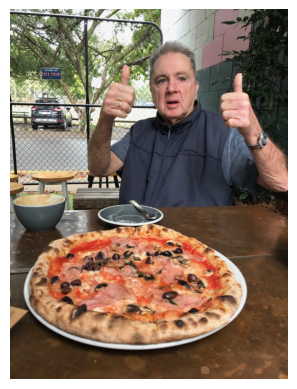

In [752]:
import torchvision
import requests
import matplotlib.pyplot as plt
from pathlib import Path

# Setup path
custom_image_path = Path("data/04-pizza-dad.jpeg")

# 1. Delete the bad 404 file if it exists
if custom_image_path.is_file():
    custom_image_path.unlink()

# 2. Download from the correct URL (04-pizza-dad.jpeg)
url = "https://raw.githubusercontent.com/mrdbourke/pytorch-deep-learning/main/data/04-pizza-dad.jpeg"
response = requests.get(url)

with open(custom_image_path, "wb") as f:
    f.write(response.content)

# 3. Read and inspect the image
custom_image_uint8 = torchvision.io.read_image(str(custom_image_path))
print(f"Custom image tensor:\n {custom_image_uint8}")
print(f"Custom image shape:\n {custom_image_uint8.shape}")
print(f"Custom image datatype: {custom_image_uint8.dtype}")

# 4. Plot the image
plt.imshow(custom_image_uint8.permute(1, 2, 0))
plt.axis(False)

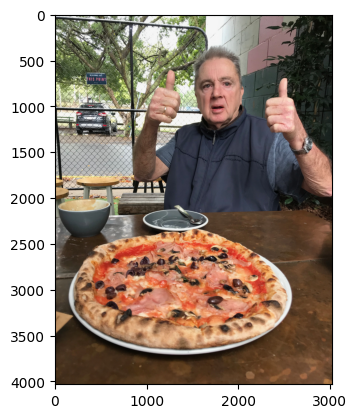

In [756]:
plt.imshow(custom_image_uint8.permute(1, 2, 0))